# Short-channel regression - physiological band power

Does the short-channel regressors reduce systemic physiology (Mayer waves, respiration, cardiac) in the long channels?

Fit GLM models, as in the main analysis but two versions:

- **full**: the complete design matrix
- **noSS**: the same design matrix without `ShortHbO` / `ShortHbR`

The only difference between the two models is the short-channel regressors. So we can see which effect the short channels have on residuals.

GLM is:

$Y=X\theta+\epsilon$

So residuals are:

$\epsilon=Y−X\theta$

or 

$\epsilon=Y−{\theta}X^T$

Power in each band is computed from the Welch PSD of the residuals.

# Set parameters and read data

In [1]:
import os

import matplotlib.pyplot as plt
import mne
import mne_bids
import mne_nirs
import numpy as np
import pandas as pd
import seaborn as sns

from itertools import compress
from scipy.integrate import trapezoid
from scipy.signal import welch
from scipy.stats import wilcoxon
from statsmodels.stats.multitest import multipletests

# BIDS dataset and task
task = "lettersearch"
bids_root = "data/lettersearch_BIDS"
datatype = 'nirs'
bids_folder = mne_bids.BIDSPath(root=bids_root, datatype=datatype)
nirs_files = bids_folder.match()

# Parameters used (same as main analysis)
sci_limit = 0.8

# Physiological bands (Hz)
BANDS = {
    "mayer":   (0.07, 0.13),
    "resp":    (0.20, 0.40),
    "cardiac": (0.80, 1.60),
}

# Welch window length (seconds)
welch_win_sec = 60

# Offsets
offsets_path = "data/trigger_offsets.csv"
if os.path.exists(offsets_path):
    trigger_offsets = pd.read_csv(offsets_path).set_index('subject')['lag_sec']
    print(f"Loaded trigger offsets for {len(trigger_offsets)} subjects:")
    print(trigger_offsets.to_string())
else:
    trigger_offsets = pd.Series(dtype=float)
    print(f"WARNING: {offsets_path} not found — no ACC offsets applied")

Loaded trigger offsets for 16 subjects:
subject
P1      0.0
P10    13.0
P11     5.0
P12     0.0
P13     0.0
P14     2.0
P15     3.0
P17     0.0
P2      0.0
P3      0.0
P4      0.0
P5      8.0
P6     -7.0
P7     45.0
P8      0.0
P9     -5.0


# Fit full and noSS models per subject

Same design matrix construction as previously. But one without short channels. Residuals of both models are converted to band power per channel.

In [2]:
def glm_residuals(raw, design_matrix):
    """Fit the GLM and return Y - X @ theta, i.e. the residuals."""
    glm_est = mne_nirs.statistics.run_glm(raw, design_matrix, noise_model="auto")
    theta = np.hstack(glm_est.theta()).T
    return raw.get_data() - theta @ design_matrix.values.T


ss_cols = ["ShortHbO", "ShortHbR"]

all_subjects = sorted(set(file.subject for file in nirs_files))

band_records = []
psd_records = {}
for subject in all_subjects:

    # Get SNIRF file for this subject
    bids_path = mne_bids.BIDSPath(subject=subject, task=task,
                            suffix=datatype, datatype=datatype,
                            root=bids_root)

    print(f"Processing {bids_path}..")
    if not os.path.exists(bids_path):
        print(f"No SNIRF file, skip: {bids_path}")
        continue

    # Raw data
    raw_intensity = mne_bids.read_raw_bids(bids_path=bids_path)

    # Apply per-subject trigger offset from alignment_notebook
    if subject in trigger_offsets.index:
        _off = float(trigger_offsets[subject])
        _ann = raw_intensity.annotations
        raw_intensity.set_annotations(mne.Annotations(
            onset       = _ann.onset + _off,
            duration    = _ann.duration,
            description = _ann.description,
        ))
        print(f"  trigger offset applied: {_off:+.3f} s")
    else:
        print(f"  no offset for {subject} — using as-is")

    # Split into long/short
    long_chs = mne_nirs.channels.get_long_channels(raw_intensity)
    short_chs = mne_nirs.channels.get_short_channels(raw_intensity)

    # Convert to OD
    raw_od_long = mne.preprocessing.nirs.optical_density(long_chs)
    raw_od_short = mne.preprocessing.nirs.optical_density(short_chs)

    # Channel quality
    sci = mne.preprocessing.nirs.scalp_coupling_index(raw_od_long)
    bad_channels = list(compress(raw_od_long.ch_names, sci < sci_limit))
    bad_channels = np.unique([channel.replace(" 760", "").replace(" 850", "") for channel in np.unique(bad_channels)]).tolist()

    # Use the MBLL to convert into hemoglobin changes
    raw_haemo_long = mne.preprocessing.nirs.beer_lambert_law(raw_od_long, ppf=0.1)
    raw_haemo_short = mne.preprocessing.nirs.beer_lambert_law(raw_od_short, ppf=0.1)

    # Create a design matrix
    design_matrix = mne_nirs.experimental_design.make_first_level_design_matrix(raw_haemo_long,
                                                                                stim_dur=5,
                                                                                drift_model="cosine",
                                                                                hrf_model="glover",
                                                                                high_pass=0.0295)
    design_matrix["ShortHbO"] = np.mean(
        raw_haemo_short.copy().pick(picks="hbo").get_data(), axis=0
    )
    design_matrix["ShortHbR"] = np.mean(
        raw_haemo_short.copy().pick(picks="hbr").get_data(), axis=0
    )

    # Add a boxcar regressor for the long pause
    onsets = raw_haemo_long.annotations.onset
    durations = raw_haemo_long.annotations.duration
    ends = onsets + durations
    gaps = onsets[1:] - ends[:-1]
    pause_idx = np.argmax(gaps)
    pause_start_sec = ends[pause_idx]
    pause_stop_sec = onsets[pause_idx+1]
    pause_regressor = np.zeros(len(raw_haemo_long.times))
    start_idx = np.searchsorted(raw_haemo_long.times, pause_start_sec)
    stop_idx = np.searchsorted(raw_haemo_long.times, pause_stop_sec)
    pause_regressor[start_idx:stop_idx] = 1.0
    design_matrix["pause"] = pause_regressor

    # Add acceleration regressors via TCCA
    aux_df = mne_nirs.io.snirf.read_snirf_aux_data(raw_intensity.filenames[0], raw_intensity)
    aux_all = aux_df.to_numpy()
    nirs_data = raw_haemo_long.copy().pick(picks="hbo").get_data().T
    reg, tcca_info = mne_nirs.experimental_design.rtcca(
        nirs_data,
        aux_all,
        tau=1,
        n_emb=3,
        ct=0.3,
        pca_fnirs = False,
        pca_aux = True,
        shrink=True
    )
    reg_names = [f"tCCA_{i}" for i in range(reg.shape[1])]
    for i, name in zip(range(reg.shape[1]), reg_names):
        design_matrix[name] = reg[:, i]

    # Fit both models
    res_full = glm_residuals(raw_haemo_long, design_matrix)
    res_noss = glm_residuals(raw_haemo_long, design_matrix.drop(columns=ss_cols))

    # Residual PSDs
    sfreq = raw_haemo_long.info["sfreq"]
    nperseg = int(welch_win_sec * sfreq)
    freqs, p_full = welch(res_full, fs=sfreq, nperseg=nperseg)
    _, p_noss = welch(res_noss, fs=sfreq, nperseg=nperseg)
    _, p_raw = welch(raw_haemo_long.get_data(), fs=sfreq, nperseg=nperseg)

    ch_names = raw_haemo_long.ch_names
    chroma = raw_haemo_long.get_channel_types()
    channel_ok = np.array([ch.split(' ')[0] not in bad_channels for ch in ch_names])

    # Band power per channel
    for band, (lo, hi) in BANDS.items():
        m = (freqs >= lo) & (freqs <= hi)
        bp_full = trapezoid(p_full[:, m], freqs[m], axis=1)
        bp_noss = trapezoid(p_noss[:, m], freqs[m], axis=1)
        band_records.append(pd.DataFrame({
            "subject": subject,
            "ch_name": ch_names,
            "Chroma": chroma,
            "channel_ok": channel_ok,
            "band": band,
            "power_noss": bp_noss,
            "power_full": bp_full,
        }))

    # Keep good-channel mean spectra per chroma for plotting
    for ch_type in ["hbo", "hbr"]:
        keep = channel_ok & (np.array(chroma) == ch_type)
        psd_records[(subject, ch_type)] = {
            "freqs": freqs,
            "raw":  p_raw[keep].mean(axis=0),
            "noSS": p_noss[keep].mean(axis=0),
            "full": p_full[keep].mean(axis=0),
        }

    print(f"  sfreq = {sfreq:.2f} Hz, bad channels: {bad_channels}")

band_df = pd.concat(band_records, ignore_index=True)
band_df["log_ratio"] = np.log10(band_df["power_full"] / band_df["power_noss"])
band_df["pct_reduction"] = 100 * (1 - band_df["power_full"] / band_df["power_noss"])
band_df.to_csv("data/ss_bandpower.csv")

print('done')

Processing data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_nirs.snirf..
Loading /Users/alexander.kvist/project_local/Perceptual-fnirs/data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_nirs.snirf
Found jitter of 0.000000% in sample times.
Reading events from data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_events.tsv.
Reading channel info from data/lettersearch_BIDS/sub-P1/nirs/sub-P1_task-lettersearch_channels.tsv.
Not fully anonymizing info - keeping hand, his_id, sex of subject_info
  trigger offset applied: +0.000 s
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
Reading 0 ... 5014  =      0.000 ...   985.793 secs...
  sfreq = 5.09 Hz, bad channels: []
Processing data/lettersearch_BIDS/sub-P10/nirs/sub-P10_task-lettersearch_nirs.snirf..
Loading /Users/alexander.kvist/project_local/Perceptual-fnirs/data/lettersearch_BIDS/sub-P10/nirs/sub-P10_task-lettersearch_nirs.snirf
Found jitter of 0.000000% in sample times.
Reading events from data/letters

# Group results

Per subject, the log10 power ratio (full / noSS) is averaged over good channels. Reduction is shown as dB attenuation.

In [3]:
subj_df = (
    band_df.query("channel_ok == True")
    .groupby(["subject", "Chroma", "band"], as_index=False)["log_ratio"]
    .mean()
)

stat_records = []

for (chroma, band), d in subj_df.groupby(["Chroma", "band"]):
    mean_lr = d["log_ratio"].mean()

    stat_records.append({
        "Chroma": chroma,
        "band": band,
        "n_subjects": len(d),
        "attenuation_db": 10 * mean_lr,
    })

stat_df = pd.DataFrame(stat_records)
stat_df.to_csv("data/ss_bandpower_stats.csv", index=False)

display(stat_df.round(3))


,Chroma,band,n_subjects,attenuation_db
0,hbo,cardiac,16,-6.082
1,hbo,mayer,16,-4.780
2,hbo,resp,16,-1.780
3,hbr,cardiac,16,-2.300
4,hbr,mayer,16,-1.350
5,hbr,resp,16,-0.663


# Residual spectra - with and without short-channel regressors

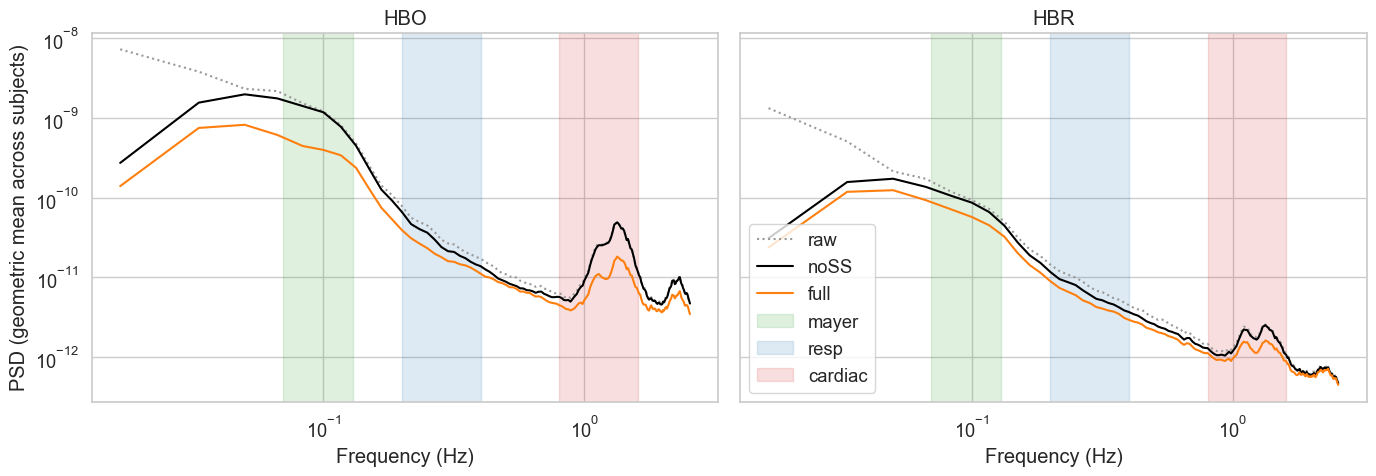

In [4]:
sns.set_theme(style="whitegrid", font_scale=1.2)
band_colors = {"mayer": "tab:green", "resp": "tab:blue", "cardiac": "tab:red"}

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, ch_type in zip(axes, ["hbo", "hbr"]):
    recs = [v for (s, c), v in psd_records.items() if c == ch_type]
    freqs = recs[0]["freqs"]
    for key, style in [("raw", dict(color="0.6", ls=":")),
                       ("noSS", dict(color="black")),
                       ("full", dict(color="tab:orange"))]:
        # Geometric mean across subjects
        psd = np.exp(np.mean([np.log(r[key]) for r in recs], axis=0))
        ax.loglog(freqs[1:], psd[1:], label=key, **style)
    for band, (lo, hi) in BANDS.items():
        ax.axvspan(lo, hi, color=band_colors[band], alpha=0.15, label=band)
    ax.set_title(ch_type.upper())
    ax.set_xlabel("Frequency (Hz)")
axes[0].set_ylabel("PSD (geometric mean across subjects)")
axes[1].legend(loc="lower left")
plt.tight_layout()
plt.show()
fig.savefig("img/ss_residual_psd.svg", bbox_inches="tight")